# Подготовка

## Импорты

In [30]:
from sklearn.preprocessing import LabelEncoder
import numpy as np

from src.dataset import DatasetStore
from src.runner import ExperimentRunner
from src.pipeline import Pipeline
from src.preprocessors import *
from src.models import *
from src.validators import *

In [31]:
import warnings
warnings.filterwarnings('ignore')

## Загрузка данных

In [32]:
df, schema = DatasetStore.load(
    "data/processed/dataset.csv",
    "data/processed/dataset.schema.json",
    include_missing=False,
)
feature_info = DatasetStore.get_feature_info(
    schema,
    include_missing=False,
)

In [33]:
columns = ['bled cut', 'albumin']
for col in columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [34]:
df["diagnosis"] = df["diagnosis"].replace(6, 5)

y = LabelEncoder().fit_transform(df['diagnosis'].values)
X = df.drop(columns=['diagnosis'])

class_labels = [0, 1]

# Сравнение

In [15]:
top_15_features = [
    "meteorism",
    "LS/cen gid",
    "rigid of abdomi",
    "Ur",
    "LS steat",
    "glu",
    "intensiv",
    "pain of adbomin",
    "Ht",
    "pain",
    "amilase",
    "s. peritonit",
    "icterus",
    "mramor cut",
    "bil",
]
X_top15 = df[top_15_features]

In [ ]:
rf = ExperimentRunner.load_pipeline('_analys/RandomForest/pipeline.joblib')
rf_top15 = ExperimentRunner.load_pipeline('_analys/RandomForestTop15/pipeline.joblib')

In [ ]:
y_pred = rf.predict(X)
y_pred_top15 = rf_top15.predict(X_top15)

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true=y, y_pred=y_pred))

In [ ]:
from mlxtend.evaluate import mcnemar_table

mcnemar_table(y, y_pred, y_pred_top15)

array([[352,  13],
       [  5,  22]])

## Графики ROC и PR

In [45]:
from pathlib import Path
import json

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

In [46]:
def collect_curves(json_paths):
    """Читает список JSON-файлов и достаёт данные для ROC и PR кривых."""
    roc_items, pr_items = [], []

    for p in json_paths:
        p = Path(p)
        full_path = "_analys" / p / "detailed.json"
        with open(full_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        label = p.stem  
        roc = data.get("holdout", {}).get("roc_curves", {}).get("binary")
        pr = data.get("holdout", {}).get("pr_curves", {}).get("binary")

        if roc is not None:
            roc_items.append((label, roc))
        if pr is not None:
            pr_items.append((label, pr))

    return roc_items, pr_items

In [47]:
json_files = [
    "RandomForest",
    "RandomForestTop5",
    "RandomForestTop10",
    "RandomForestTop15",
    "RandomForestTop14",
]
roc_items, pr_items = collect_curves(json_files)

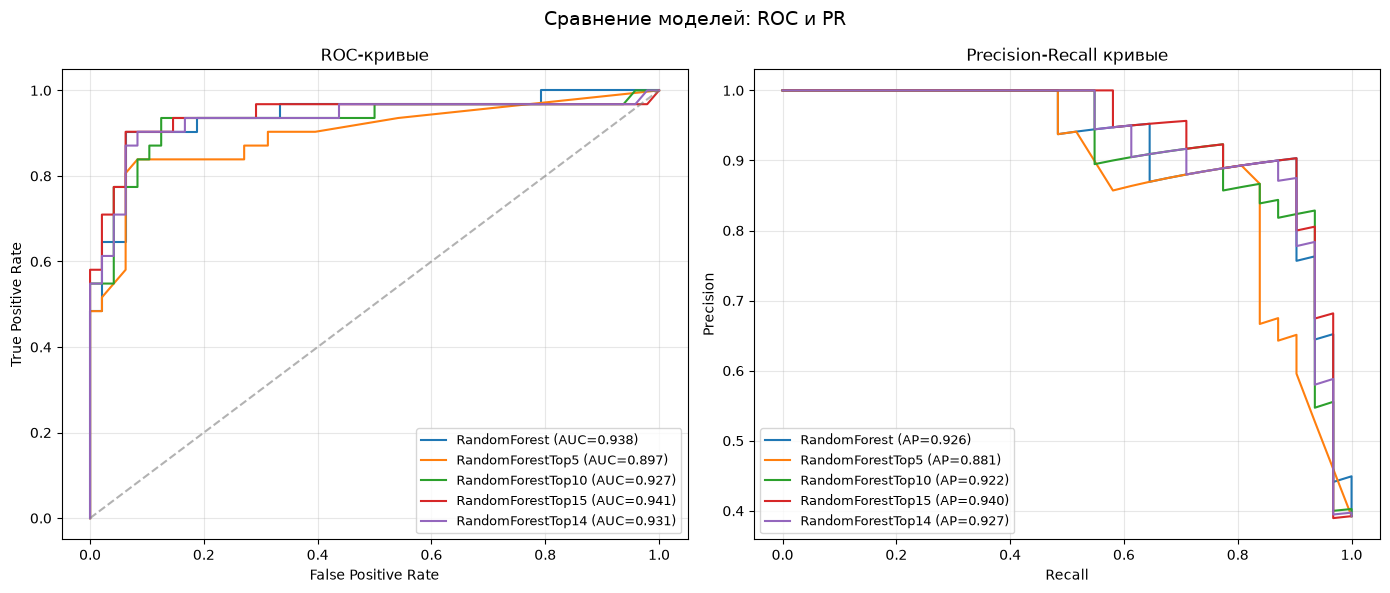

In [48]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 6))

# ---------- ROC ----------
for label, roc in roc_items:
    auc = roc.get("auc")
    name = f"{label} (AUC={auc:.3f})" if auc is not None else label
    ax_roc.plot(roc["fpr"], roc["tpr"], label=name)

ax_roc.plot([0, 1], [0, 1], linestyle="--", color="gray", alpha=0.6)
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.set_title("ROC-кривые")
ax_roc.legend(loc="lower right", fontsize=9)
ax_roc.grid(True, alpha=0.3)

# ---------- PR ----------
for label, pr in pr_items:
    ap = pr.get("average_precision")
    name = f"{label} (AP={ap:.3f})" if ap is not None else label
    ax_pr.plot(pr["recall"], pr["precision"], label=name)

ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.set_title("Precision-Recall кривые")
ax_pr.legend(loc="lower left", fontsize=9)
ax_pr.grid(True, alpha=0.3)

fig.suptitle("Сравнение моделей: ROC и PR", fontsize=14)
fig.tight_layout()

plt.show()